Original dimensions: (1000, 10)
Reduced dimensions: (1000, 9)
Variance retained: 99.94 %


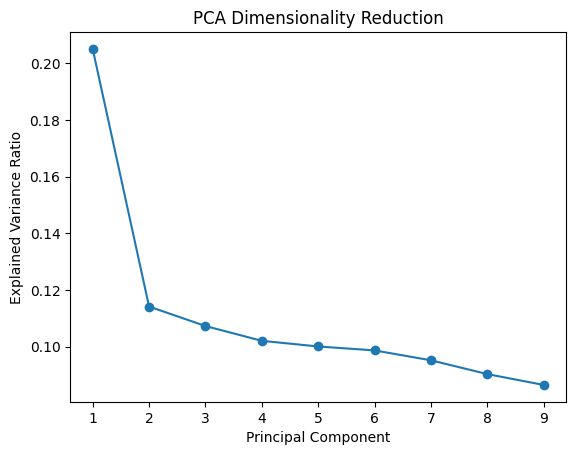

In [3]:

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

df = pd.read_csv("diabetes_data.csv")
X = df.drop(columns=["user_id", "date", "risk_score"])
X = X.select_dtypes(include="number").fillna(X.median())

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

pca = PCA(n_components=0.95)
X_reduced = pca.fit_transform(X_scaled)

print("Original dimensions:", X_scaled.shape)
print("Reduced dimensions:", X_reduced.shape)
print("Variance retained:", round(sum(pca.explained_variance_ratio_) * 100, 2), "%")

plt.plot(range(1, len(pca.explained_variance_ratio_) + 1), pca.explained_variance_ratio_, marker="o")
plt.xlabel("Principal Component")
plt.ylabel("Explained Variance Ratio")
plt.title("PCA Dimensionality Reduction")
plt.show()


In [2]:

import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

df = pd.read_csv("diabetes_data.csv")

X = df.drop(columns=["user_id", "date", "risk_score"])
X = X.select_dtypes(include="number").fillna(X.median())
y = (df["risk_score"] >= df["risk_score"].median()).astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

model = GaussianNB()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("Classification Report:\n", classification_report(y_test, y_pred))


Accuracy: 0.86
Confusion Matrix:
 [[85 15]
 [13 87]]
Classification Report:
               precision    recall  f1-score   support

           0       0.87      0.85      0.86       100
           1       0.85      0.87      0.86       100

    accuracy                           0.86       200
   macro avg       0.86      0.86      0.86       200
weighted avg       0.86      0.86      0.86       200



Linear SVM Accuracy: 0.72
Non-linear SVM (RBF) Accuracy: 0.71


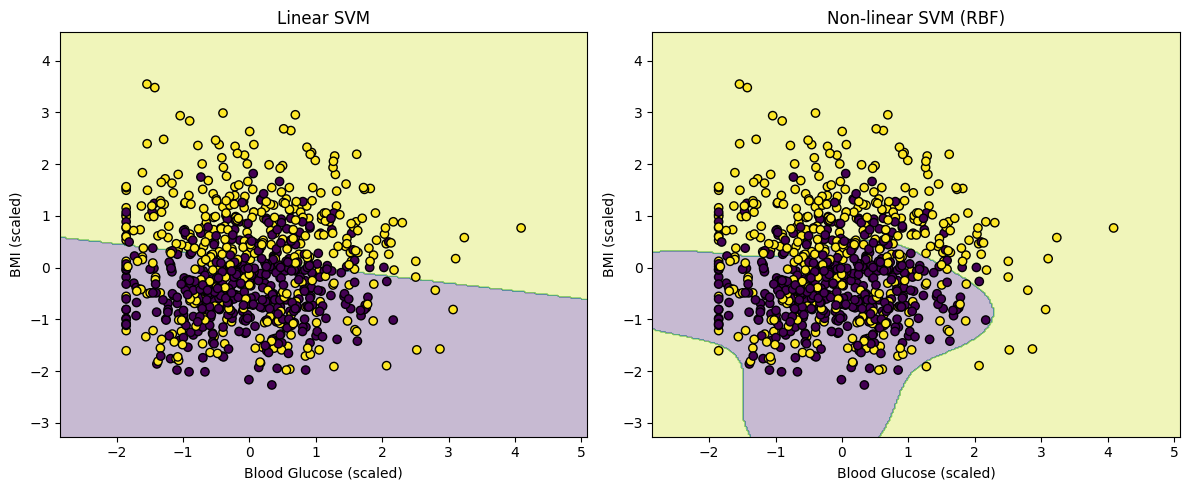

In [4]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

df = pd.read_csv("diabetes_data.csv")

X = df[["blood_glucose", "bmi"]].fillna(df[["blood_glucose", "bmi"]].median())
y = (df["risk_score"] >= df["risk_score"].median()).astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

models = [
    SVC(kernel="linear"),
    SVC(kernel="rbf")
]

titles = ["Linear SVM", "Non-linear SVM (RBF)"]

x_min, x_max = X_train_scaled[:, 0].min() - 1, X_train_scaled[:, 0].max() + 1
y_min, y_max = X_train_scaled[:, 1].min() - 1, X_train_scaled[:, 1].max() + 1

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 300),
    np.linspace(y_min, y_max, 300)
)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for model, title, ax in zip(models, titles, axes):
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)

    print(title, "Accuracy:", accuracy_score(y_test, y_pred))

    Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)

    ax.contourf(xx, yy, Z, alpha=0.3)
    ax.scatter(
        X_train_scaled[:, 0],
        X_train_scaled[:, 1],
        c=y_train,
        edgecolors="black"
    )
    ax.set_title(title)
    ax.set_xlabel("Blood Glucose (scaled)")
    ax.set_ylabel("BMI (scaled)")

plt.tight_layout()
plt.show()
